In [142]:
from typing import Literal, TypedDict, TypeAlias, Any, TypeVar

import numpy as np

In [143]:
##########
# Types
##########

S = TypeVar("S", bound=tuple[int, ...])

MuellerMatrix: TypeAlias = np.ndarray[tuple[Literal[4], Literal[4]], np.dtype[np.floating]]
StokesVector: TypeAlias = np.ndarray[tuple[Literal[4], ], np.dtype[np.floating]]
DepolarizationCoeffs: TypeAlias = np.ndarray[tuple[Literal[9], ], np.dtype[np.floating]]

Configuration: TypeAlias = tuple[StokesVector, MuellerMatrix]
Measurements: TypeAlias = np.ndarray[tuple[int], np.dtype[np.floating]]

class MaterialProperties(TypedDict):
    # List of 9 depolarization coefficients.
    d_coeffs: DepolarizationCoeffs
    # Absorption coefficient for horizontal polarization.
    ax: float
    # Absorption coefficient for vertical polarization.
    ay: float
    # Absorption coefficient for circular polarization.
    ac: float
    # Isotropic absorption coefficient.
    a: float
    # Linear birefringence phase shift (in radians).
    delta: float
    # Circular birefringence phase shift (in radians).
    theta: float


class ElementProperties(MaterialProperties):
    # Rotation angle in radians.
    phi: float


class Error(TypedDict):
    # Absolute difference between the matrices.
    difference: np.ndarray[S, np.dtype[np.float64]]
    # Frobenius norm of the difference.
    error_norm: float | np.floating

In [144]:
###################
# Mueller Matrices
###################

def linear_polarizer(angle: float) -> MuellerMatrix:
    """Apply the Mueller matrix of a linear polarizer at a given angle to a Stokes vector.

    Parameters
    ----------
    angle: float
        angle of the polarizer in radians.

    Returns
    -------
    numpy.ndarray
        A 4x4 rotation matrix.
    """

    return linear_diattenuator(1, 0, angle)


def linear_retarder(retardance: float, angle: float) -> MuellerMatrix:
    """Generate a linear retarder Muller matrix

    Args:
        retardance (float): Phase retardance.
        angle (float): Angle with respect to fast axis.

    Returns:
        MuellerMatrix: 
    """    
    LR = np.array([
        [1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, np.cos(retardance), np.sin(retardance)],
        [0, 0, -np.sin(retardance), np.cos(retardance)],
    ])

    return rotation_matrix(-angle) @ LR @ rotation_matrix(angle)


def linear_diattenuator(tmax: float, tmin: float, angle: float) -> MuellerMatrix:
    """Creates the Mueller matrix of a linear diattenuator

    Args:
        tmax (float): Maximum transmission.
        tmin (float): Minimum transmission.
        angle (float): Maximum transmission angle.

    Returns:
        MuellerMatrix: 
    """
    LD = np.array([
        [tmax + tmin, tmax - tmin, 0, 0],
        [tmax - tmin, tmax + tmin, 0, 0],
        [0, 0, 2 * np.sqrt(tmax * tmin), 0],
        [0, 0, 0, 2 * np.sqrt(tmax * tmin)]
    ])/2
    return rotation_matrix(-angle) @ LD @ rotation_matrix(angle)


def quarter_waveplate(angle: float) -> MuellerMatrix:
    """Mueller matrix of a quarter-wave plate at a given orientation angle.

    Parameters
    ----------
    angle: float
        angle of the quarter waveplate in radians.

    Returns
    -------
    numpy.ndarray
        A 4x4 rotation matrix.
    """
    return linear_retarder(np.pi / 2, angle)


def rotation_matrix(angle: float) -> MuellerMatrix:
    """Generate the rotation matrix for a given angle.

    Parameters
    ----------
    phi : float
        Rotation angle in radians.

    Returns
    -------
    numpy.ndarray
        A 4x4 rotation matrix.
    """

    return np.array([
        [1, 0, 0, 0],
        [0,  np.cos(2 * angle), np.sin(2 * angle), 0],
        [0, -np.sin(2 * angle), np.cos(2 * angle), 0],
        [0, 0, 0, 1]
    ], dtype=np.float64) # type: ignore[no-untyped-call]


def depolarization_matrix(d_coeffs: DepolarizationCoeffs) -> MuellerMatrix:
    """Generate the depolarization matrix.

    Parameters
    ----------
    d_coeffs : list of float
        List of 9 depolarization coefficients.

    Returns
    -------
    numpy.ndarray
        A 4x4 depolarization matrix.
    """

    frobenius_norm = np.linalg.norm(d_coeffs)
    assert frobenius_norm <= 1, "Depolarization coefficients must satisfy Frobenius norm <= 1."

    d11, d12, d13, d21, d22, d23, d31, d32, d33 = d_coeffs
    return np.array([
        [1, 0, 0, 0],
        [0, d11, d12, d13],
        [0, d21, d22, d23],
        [0, d31, d32, d33]
    ], dtype=np.float64) # type: ignore[no-untyped-call]


def generate_valid_depolarization_coeffs() -> DepolarizationCoeffs:
    """Generate a random set of valid depolarization coefficients satisfying the Frobenius norm constraint.

    Returns
    -------
    list of float
        List of 9 depolarization coefficients.
    """
    coeffs = np.random.uniform(0, 1, 9)
    frobenius_norm = np.linalg.norm(coeffs)

    if frobenius_norm > 1:
        return coeffs / frobenius_norm  # Normalize to satisfy Frobenius norm
    return coeffs


def dichroism_matrix(ax: float, ay: float, ac: float, a: float) -> MuellerMatrix:
    """Generate the dichroism matrix.

    Parameters
    ----------
    ax : float
        Absorption coefficient for horizontal polarization.
    ay : float
        Absorption coefficient for vertical polarization.
    ac : float
        Absorption coefficient for circular polarization.
    a : float
        Isotropic absorption coefficient.

    Returns
    -------
    numpy.ndarray
        A 4x4 dichroism matrix.
    """
    return np.array([
        [np.exp(-a), np.exp(-ax), 0, np.exp(-ac)],
        [np.exp(-ax), np.exp(-ax), 0, 0],
        [0, 0, np.exp(-ay), 0],
        [np.exp(-ac), 0, 0, np.exp(-ac)]
    ], dtype=np.float64) # type: ignore[no-untyped-call]


def birefringence_matrix(delta: float, theta: float) -> MuellerMatrix:
    """Generate the birefringence matrix.

    Parameters
    ----------
    delta : float
        Linear birefringence phase shift (in radians).
    theta : float
        Circular birefringence phase shift (in radians).

    Returns
    -------
    numpy.ndarray
        A 4x4 birefringence matrix.
    """
    M_linear = np.array([
        [1, 0, 0, 0],
        [0,  np.cos(delta), np.sin(delta), 0],
        [0, -np.sin(delta), np.cos(delta), 0],
        [0, 0, 0, 1]
    ], dtype=np.float64)

    M_circular = np.array([
        [1, 0, 0, 0],
        [0,  np.cos(theta), 0, np.sin(theta)],
        [0, 0, 1, 0],
        [0, -np.sin(theta), 0, np.cos(theta)]
    ], dtype=np.float64)

    return M_linear @ M_circular # type: ignore[no-untyped-call]


def combined_mueller_matrix(phi: float, d_coeffs: DepolarizationCoeffs, ax: float, ay: float, ac: float, a: float, delta: float, theta: float) -> MuellerMatrix:
    """Generate the full Mueller matrix including rotation, depolarization, dichroism, and birefringence.

    Parameters
    ----------
    phi : float
        Material orientation angle in radians.
    d_coeffs : list of float
        List of 9 depolarization coefficients.
    ax : float
        Absorption coefficient for horizontal polarization.
    ay : float
        Absorption coefficient for vertical polarization.
    ac : float
        Absorption coefficient for circular polarization.
    a : float
        Isotropic absorption coefficient.
    delta : float
        Linear birefringence phase shift (in radians).
    theta : float
        Circular birefringence phase shift (in radians).

    Returns
    -------
    numpy.ndarray
        The full 4x4 Mueller matrix.
    """
    R_neg_phi = rotation_matrix(-phi)
    R_phi = rotation_matrix(phi)
    M_depol = depolarization_matrix(d_coeffs)
    M_dichroism = dichroism_matrix(ax, ay, ac, a)
    M_birefringence = birefringence_matrix(delta, theta)

    return R_neg_phi @ M_depol @ M_dichroism @ M_birefringence @ R_phi # type: ignore[no-untyped-call]


In [145]:
LP = linear_polarizer(np.pi/2)
LD = linear_diattenuator(1, 0, np.pi/2)
print(LD - LP)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [146]:
##############
# Simulations
##############

def simulate_measurements(mueller_matrix: MuellerMatrix, measurement_config: list[Configuration]) -> Measurements:
    """Simulate output intensities for a given Mueller matrix and measurement configuration.

    Parameters
    ----------
    mueller_matrix : numpy.ndarray
        A 4x4 Mueller matrix representing the material.
    measurement_config : list of tuples
        Each tuple contains:
        - input_stokes (numpy.ndarray): A 1D array representing the input Stokes vector.
        - analyzer_mueller (numpy.ndarray): Analyzer mueller matrix.

    Returns
    -------
    numpy.ndarray
        Simulated output intensities for the provided measurement configuration.
    """
    output_intensities: list[float] = []
    for input_stokes, analyzer_mueller in measurement_config:
        output_stokes = mueller_matrix @ input_stokes
        intensity = (analyzer_mueller @ output_stokes)[0]
        assert isinstance(intensity, np.floating), "Intensity must be a floating point number."
        assert intensity >= 0, "Intensity must be non-negative."
        output_intensities.append(intensity)

    return np.array(output_intensities)


def reconstruct_mueller_matrix(measurements: Measurements, measurement_config: list[Configuration]) -> MuellerMatrix:
    """Reconstruct the Mueller matrix from simulated measurements.

    Parameters
    ----------
    measurements : numpy.ndarray
        Array of simulated output intensities.
    measurement_config : list of tuples
        Each tuple contains:
        - input_stokes (numpy.ndarray): The input Stokes vector.
        - analyzer_mueller (numpy.ndarray): Analyzer mueller matrix.

    Returns
    -------
    numpy.ndarray
        The reconstructed 4x4 Mueller matrix.
    """

    assert len(measurements) == len(measurement_config), "Measurements and configuration lengths must match."

    K = []

    for input_stokes, analyzer_mueller in measurement_config:
        # Outer product entre A[0,:] (la fila que da la intensidad) y S
        K_i = np.kron(analyzer_mueller[0, :], input_stokes)  # Esto es vector de tamaño 16
        K.append(K_i)

    K = np.vstack(K)
    m = np.linalg.lstsq(K, measurements, rcond=None)[0]

    return m.reshape(4, 4)

# A x = y 

In [147]:
###########
# Metrics
###########

def compare_matrices(true_matrix: np.ndarray[S, Any], reconstructed_matrix: np.ndarray[S, Any]) -> Error[S]:
    """Compare the true Mueller matrix with the reconstructed Mueller matrix.

    Parameters
    ----------
    true_matrix : numpy.ndarray
        The original Mueller matrix used for simulation.
    reconstructed_matrix : numpy.ndarray
        The Mueller matrix reconstructed from simulated measurements.

    Returns
    -------
    dict
        A dictionary containing:
        - "difference": The absolute difference between the matrices.
        - "error_norm": The Frobenius norm of the difference.
    """
    difference = np.abs(true_matrix - reconstructed_matrix)
    error_norm = np.linalg.norm(difference)

    return {
        "difference": difference,
        "error_norm": error_norm
    }


def extract_parameters(mueller_matrix: MuellerMatrix) -> ElementProperties:
    """Extract physical parameters (phi, d_coeffs, ax, ay, ac, a, delta, theta) from the Mueller matrix.

    Parameters
    ----------
    mueller_matrix : numpy.ndarray
        The reconstructed 4x4 Mueller matrix.

    Returns
    -------
    dict
        Extracted parameters.
    """
    phi = 0.5 * np.arctan2(mueller_matrix[1, 2], mueller_matrix[1, 1])
    phi_deg = np.degrees(phi)

    R_neg_phi = rotation_matrix(-phi_deg)
    M_no_rotation = R_neg_phi @ mueller_matrix @ rotation_matrix(phi_deg)

    depol_submatrix = M_no_rotation[1:, 1:]
    frobenius_norm = np.sqrt(np.sum(depol_submatrix**2))
    assert frobenius_norm <= 1, "Depolarization coefficients violate Frobenius norm constraint."
    d_coeffs = depol_submatrix.flatten()

    ax = -np.log(M_no_rotation[0, 1])
    ay = -np.log(M_no_rotation[0, 2])
    ac = -np.log(M_no_rotation[0, 3])
    a = -np.log(M_no_rotation[0, 0])

    birefringence_submatrix = M_no_rotation[1:, 1:]
    delta = np.arctan2(birefringence_submatrix[1, 2], birefringence_submatrix[1, 1])
    theta = np.arctan2(birefringence_submatrix[0, 2], birefringence_submatrix[0, 0])

    return {
        "phi": phi_deg,
        "d_coeffs": d_coeffs,
        "ax": ax,
        "ay": ay,
        "ac": ac,
        "a": a,
        "delta": delta,
        "theta": theta
    }


## Ejemplo

In [148]:
material = {
    "d_coeffs": generate_valid_depolarization_coeffs() * .5,
    "ax": 0.1,
    "ay": 0.2,
    "ac": 0.05,
    "a": 0.15,
    "delta": np.pi / 4,
    "theta": np.pi / 6,
}

element = {
  "phi": np.radians(30),
  **material
}

M = combined_mueller_matrix(**element)

In [149]:
print("Element vs. extracted from M")
for key, value in element.items():
  if key == "d_coeffs":
    for ndx, coeff in enumerate(value):
      print(f"{key}[{ndx}]: {value[ndx]} vs. {element[key][ndx]}")
  else:
    print(f"{key}: {value} vs. {element[key]}")

Element vs. extracted from M
phi: 0.5235987755982988 vs. 0.5235987755982988
d_coeffs[0]: 0.23213465609884884 vs. 0.23213465609884884
d_coeffs[1]: 0.20225997655030603 vs. 0.20225997655030603
d_coeffs[2]: 0.24718005661513606 vs. 0.24718005661513606
d_coeffs[3]: 0.1899044658456639 vs. 0.1899044658456639
d_coeffs[4]: 0.028628864143008553 vs. 0.028628864143008553
d_coeffs[5]: 0.08590431380570931 vs. 0.08590431380570931
d_coeffs[6]: 0.18712845518881233 vs. 0.18712845518881233
d_coeffs[7]: 0.04703726009558482 vs. 0.04703726009558482
d_coeffs[8]: 0.11231202614212926 vs. 0.11231202614212926
ax: 0.1 vs. 0.1
ay: 0.2 vs. 0.2
ac: 0.05 vs. 0.05
a: 0.15 vs. 0.15
delta: 0.7853981633974483 vs. 0.7853981633974483
theta: 0.5235987755982988 vs. 0.5235987755982988


In [150]:
input_stokes: list[StokesVector] = [
    np.array([1, 1, 0, 0]),
    np.array([1, -1, 0, 0]),
    np.array([1, 0, 1, 0]),
    np.array([1, 0, 0, 1])
]

measurement_config = [
    (s, linear_polarizer(a)) for s in input_stokes for a in np.radians([0, 45, 90, 135])
    ] + [
    (s, linear_polarizer(0) @ quarter_waveplate(a)) for s in input_stokes for a in np.radians([0, 45])
]

measurements = simulate_measurements(M, measurement_config)


(23, 4, 4)


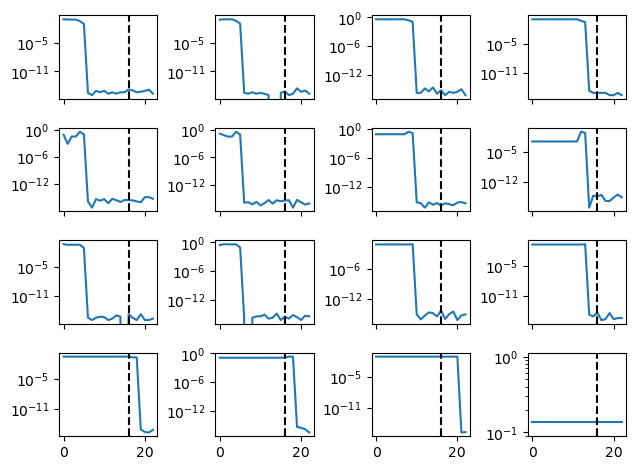

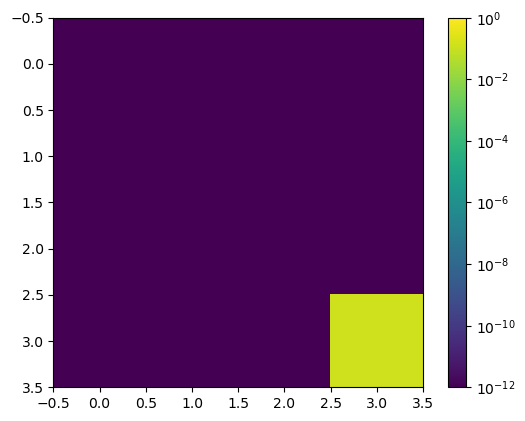

In [158]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

differences = []
for i in range(1, len(measurements)):
    M_reconstructed = reconstruct_mueller_matrix(measurements[0:i], measurement_config[0:i])
    differences.append(np.abs(M_reconstructed - M))

differences = np.array(differences)
print(differences.shape)

fig, axs = plt.subplots(4, 4, sharex=True)
x = np.arange(differences.shape[0])
plt.tight_layout()
for i in range(len(axs)):
    for j in range(len(axs[0])):
        ax = axs[i][j]

        ax.set_yscale('log')
        ax.plot(x, differences[:, i, j])
        ax.axvline(16, linestyle="dashed", color="k")

plt.figure()
vmin=1e-12
vmax=1

plt.imshow(differences[-1, :, :], norm=LogNorm(vmin=vmin, vmax=vmax))
plt.colorbar()
plt.show()

In [152]:
M_reconstructed = reconstruct_mueller_matrix(measurements, measurement_config)



In [153]:
print("Number of measurements:", len(measurements))
print("Original Mueller Matrix:")
print(M)
print("\nReconstructed Mueller Matrix:")
print(M_reconstructed)

Number of measurements: 24
Original Mueller Matrix:
[[ 0.86070798 -0.5148561   0.38787642  1.14369718]
 [ 0.00300606 -0.05570031 -0.07001615  0.00294737]
 [ 0.51230141 -0.28561952  0.10343452  0.25156896]
 [ 0.27615533 -0.11392681  0.09659136  0.13876971]]

Reconstructed Mueller Matrix:
[[ 0.86070798 -0.5148561   0.38787642  1.14369718]
 [ 0.00300606 -0.05570031 -0.07001615  0.00294737]
 [ 0.51230141 -0.28561952  0.10343452  0.25156896]
 [ 0.27615533 -0.11392681  0.09659136  0.13876971]]


In [154]:
comparison = compare_matrices(M, M_reconstructed)
print("\nComparison Results:")
print(f"Difference:\n{comparison['difference']}")
print(f"Error Frobenius Norm: {comparison['error_norm']}")


Comparison Results:
Difference:
[[9.99200722e-16 6.66133815e-16 3.88578059e-16 2.22044605e-16]
 [3.81639165e-16 9.71445147e-17 3.19189120e-16 2.22911967e-16]
 [1.33226763e-15 3.33066907e-16 5.68989300e-16 7.21644966e-16]
 [1.05471187e-15 2.22044605e-16 4.16333634e-16 3.60822483e-16]]
Error Frobenius Norm: 2.4788562661301017e-15


In [155]:
print("Element vs. extracted from M_reconstructed")
for key, value in element.items():
  if key == "d_coeffs":
    for ndx, coeff in enumerate(value):
      print(f"{key}[{ndx}]: {value[ndx]} vs. {element[key][ndx]}")
  else:
    print(f"{key}: {value} vs. {element[key]}")

Element vs. extracted from M_reconstructed
phi: 0.5235987755982988 vs. 0.5235987755982988
d_coeffs[0]: 0.23213465609884884 vs. 0.23213465609884884
d_coeffs[1]: 0.20225997655030603 vs. 0.20225997655030603
d_coeffs[2]: 0.24718005661513606 vs. 0.24718005661513606
d_coeffs[3]: 0.1899044658456639 vs. 0.1899044658456639
d_coeffs[4]: 0.028628864143008553 vs. 0.028628864143008553
d_coeffs[5]: 0.08590431380570931 vs. 0.08590431380570931
d_coeffs[6]: 0.18712845518881233 vs. 0.18712845518881233
d_coeffs[7]: 0.04703726009558482 vs. 0.04703726009558482
d_coeffs[8]: 0.11231202614212926 vs. 0.11231202614212926
ax: 0.1 vs. 0.1
ay: 0.2 vs. 0.2
ac: 0.05 vs. 0.05
a: 0.15 vs. 0.15
delta: 0.7853981633974483 vs. 0.7853981633974483
theta: 0.5235987755982988 vs. 0.5235987755982988


### Replicando el paper